In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

# ==========================================
# 1. SPECIFING Target CROPS & LOAD DATA
# ==========================================
crops_list = [
    'Maize', 'Wheat', 'Soybean', 'Sunflower', 
    'Groundnuts', 'Beans', 'Cotton', 'Sorghum'
]

np.random.seed(42)
n_samples = 1600

df = pd.DataFrame({
    'crop': np.random.choice(crops_list, size=n_samples),
    'rainfall': np.random.uniform(200, 1400, size=n_samples),          # mm
    'frost_level': np.random.uniform(0, 15, size=n_samples),           # frost days/index
    'temperature': np.random.uniform(12, 38, size=n_samples),          # °C
    'solar_radiation': np.random.uniform(10, 30, size=n_samples),     # MJ/m²/day
    'wind_speed': np.random.uniform(1, 25, size=n_samples),           # km/h
    'yield_t_ha': np.random.uniform(0.5, 9.0, size=n_samples)         # tons/hectare
})

# ==========================================
# 2. FEATURE & TARGET SEPARATION & PIPELINE
# ==========================================
X = df[['crop', 'rainfall', 'frost_level', 'temperature', 'solar_radiation', 'wind_speed']]
y = df['yield_t_ha']

# Preprocess categorical crop column
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['crop']),
        ('num', 'passthrough', ['rainfall', 'frost_level', 'temperature', 'solar_radiation', 'wind_speed'])
    ]
)

# Build pipeline with XGBoost
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=150, 
        learning_rate=0.07, 
        max_depth=5, 
        random_state=42
    ))
])

# Train model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
model_pipeline.fit(X_train, y_train)

# ==========================================
# 3. YIELD EVALUATION & RECOMMENDATION FUNCTION
# ==========================================
def recommend_crop(field_conditions, crop_candidates, pipeline):
    """
    Evaluates all 8 crops under the given weather/field conditions 
    and returns a ranked DataFrame of predicted yields.
    """
    results = []

    for crop_name in crop_candidates:
 
        scenario = pd.DataFrame([{
            'crop': crop_name,
            'rainfall': field_conditions['rainfall'],
            'frost_level': field_conditions['frost_level'],
            'temperature': field_conditions['temperature'],
            'solar_radiation': field_conditions['solar_radiation'],
            'wind_speed': field_conditions['wind_speed']
        }])
        
        # Predict yield for this crop
        predicted_yield = pipeline.predict(scenario)[0]
        results.append({
            'Crop': crop_name, 
            'Predicted Yield (t/ha)': round(predicted_yield, 2)
        })

    # Sort results from highest to lowest yield
    ranking_df = pd.DataFrame(results).sort_values(by='Predicted Yield (t/ha)', ascending=False).reset_index(drop=True)
    return ranking_df

# ==========================================
# 4. RUN ON SAMPLE FIELD CONDITIONS
# ==========================================
# Enter environmental values for a given location or season
current_field_conditions = {
    'rainfall': 100.0,         # Annual or seasonal rainfall (mm)
    'frost_level': 1.0,         # Low frost level
    'temperature': 25.0,        # Average temperature (°C)
    'solar_radiation': 22.5,    # MJ/m²/day
    'wind_speed': 9.0           # km/h
}

yield_predictions = recommend_crop(current_field_conditions, crops_list, model_pipeline)

# Display All Crop Yield Predictions
print("=== PREDICTED YIELDS FOR ALL 8 CROPS ===")
print(yield_predictions.to_string(index=False))

# Display Top Recommendation
best_crop = yield_predictions.iloc[0]['Crop']
top_yield = yield_predictions.iloc[0]['Predicted Yield (t/ha)']

print("\n" + "="*45)
print(f"🌟 TOP RECOMMENDED CROP : {best_crop.upper()}")
print(f"📈 EXPECTED YIELD     : {top_yield} tons/hectare")
print("="*45)

=== PREDICTED YIELDS FOR ALL 8 CROPS ===
      Crop  Predicted Yield (t/ha)
Groundnuts                    7.85
     Maize                    7.71
    Cotton                    7.63
 Sunflower                    7.52
   Soybean                    7.43
     Beans                    7.36
   Sorghum                    7.12
     Wheat                    5.77

🌟 TOP RECOMMENDED CROP : GROUNDNUTS
📈 EXPECTED YIELD     : 7.849999904632568 tons/hectare


In [3]:
import joblib

# Save the entire pipeline (includes the preprocessor + XGBoost model)
joblib.dump(model_pipeline, 'crop_yield_model.joblib')

print("Model successfully saved to 'crop_yield_model.joblib'!")

Model successfully saved to 'crop_yield_model.joblib'!


AgriWeather Model Performance
--------------------------------
MAE  : 2.1668
MSE  : 6.7182
RMSE : 2.5919
R²   : -0.1949


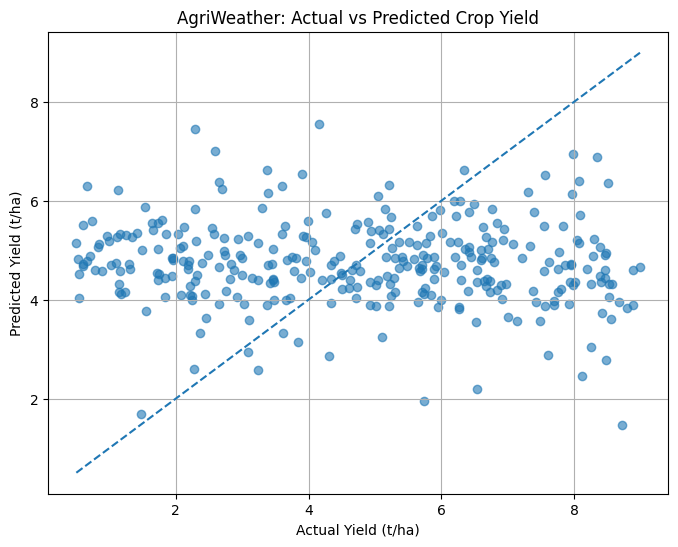

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
y_pred = model_pipeline.predict(X_test)

# Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("AgriWeather Model Performance")
print("--------------------------------")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

# Actual vs Predicted
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Yield (t/ha)")
plt.ylabel("Predicted Yield (t/ha)")
plt.title("AgriWeather: Actual vs Predicted Crop Yield")
plt.grid(True)

plt.show()

In [5]:
import pandas as pd

df = pd.read_csv("crop data.csv")

print("Shape:", df.shape)
print("\nColumns:")
for i, col in enumerate(df.columns):
    print(f"{i:2d}: {repr(col)}")

Shape: (800, 7)

Columns:
 0: 'crop'
 1: 'rainfall_mm'
 2: 'frost_level_c'
 3: 'temperature_c'
 4: 'solar_radiation_MJ_m2'
 5: 'wind_speed_m_s'
 6: 'yield_t_ha'


Correlation Matrix:
                       rainfall_mm  frost_level_c  temperature_c  \
rainfall_mm                  1.000          0.303          0.128   
frost_level_c                0.303          1.000          0.522   
temperature_c                0.128          0.522          1.000   
solar_radiation_MJ_m2       -0.061          0.306          0.477   
wind_speed_m_s              -0.138         -0.015          0.059   
yield_t_ha                   0.025         -0.042         -0.025   

                       solar_radiation_MJ_m2  wind_speed_m_s  yield_t_ha  
rainfall_mm                           -0.061          -0.138       0.025  
frost_level_c                          0.306          -0.015      -0.042  
temperature_c                          0.477           0.059      -0.025  
solar_radiation_MJ_m2                  1.000           0.085       0.036  
wind_speed_m_s                         0.085           1.000       0.029  
yield_t_ha                             0.036         

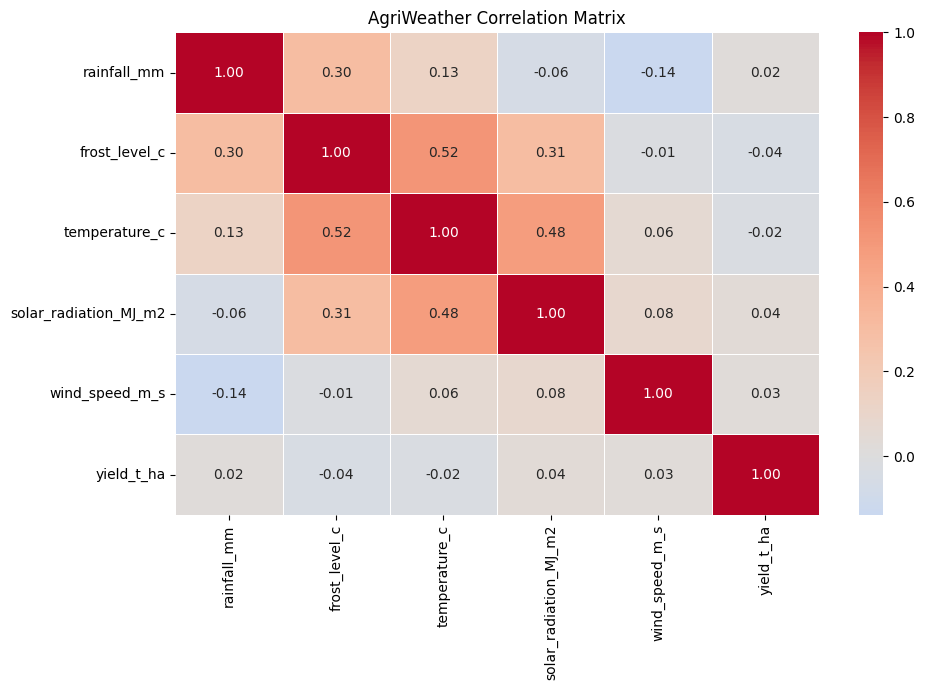

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("crop data.csv")

# Select numerical variables
correlation_data = df[
    [
        'rainfall_mm',
        'frost_level_c',
        'temperature_c',
        'solar_radiation_MJ_m2',
        'wind_speed_m_s',
        'yield_t_ha'
    ]
]

# Calculate correlations
correlation_matrix = correlation_data.corr()

# Display correlation values
print("Correlation Matrix:")
print(correlation_matrix.round(3))

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("AgriWeather Correlation Matrix")
plt.tight_layout()
plt.show()

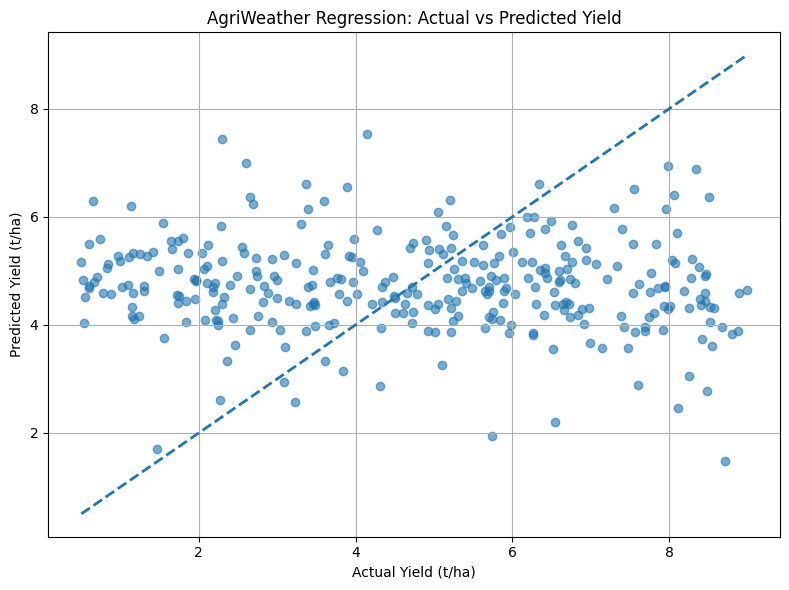

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# REGRESSION / ACTUAL VS PREDICTED GRAPH
# ==========================================

plt.figure(figsize=(8, 6))

# Scatter plot
plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    linewidth=2
)

plt.xlabel("Actual Yield (t/ha)")
plt.ylabel("Predicted Yield (t/ha)")

plt.title("AgriWeather Regression: Actual vs Predicted Yield")

plt.grid(True)
plt.tight_layout()

plt.show()

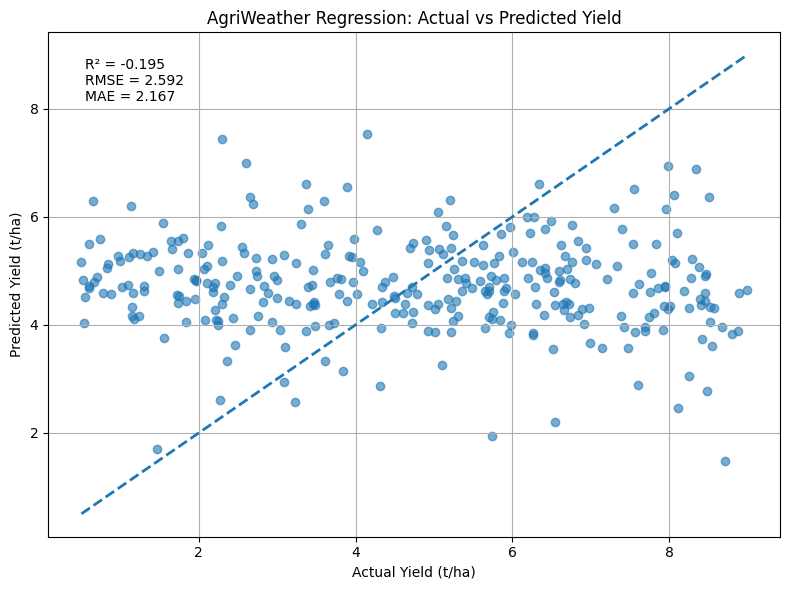

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    linewidth=2
)

plt.xlabel("Actual Yield (t/ha)")
plt.ylabel("Predicted Yield (t/ha)")
plt.title("AgriWeather Regression: Actual vs Predicted Yield")

plt.text(
    0.05,
    0.95,
    f"R² = {r2:.3f}\nRMSE = {rmse:.3f}\nMAE = {mae:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment='top'
)

plt.grid(True)
plt.tight_layout()
plt.show()

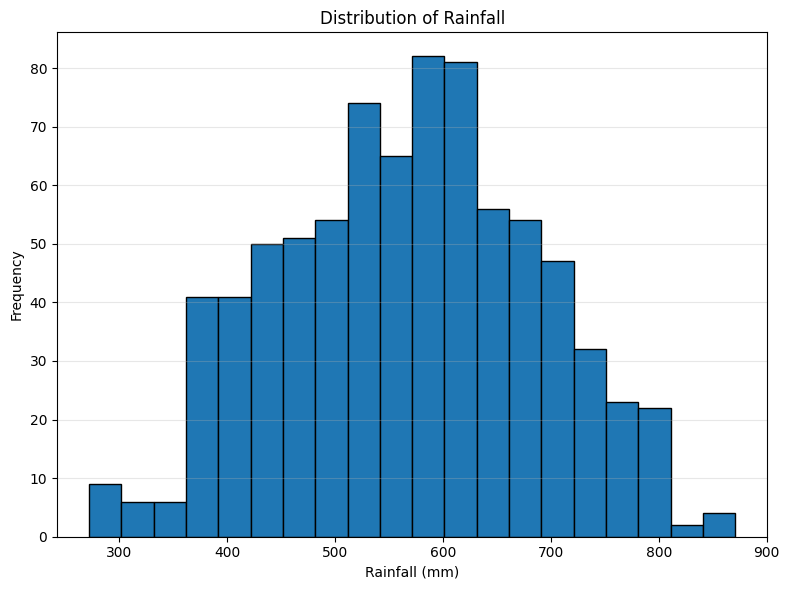

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("crop data.csv")

plt.figure(figsize=(8, 6))

plt.hist(
    df["rainfall_mm"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")
plt.title("Distribution of Rainfall")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [10]:
print(df.describe())

       rainfall_mm  frost_level_c  temperature_c  solar_radiation_MJ_m2  \
count   800.000000     800.000000     800.000000              800.00000   
mean    567.778375       2.901375      23.989875               20.16925   
std     118.733967       1.977226       4.259711                2.60182   
min     272.100000      -3.500000      10.400000               13.80000   
25%     477.925000       1.775000      21.875000               18.30000   
50%     572.100000       2.900000      24.500000               20.20000   
75%     655.675000       4.200000      27.000000               22.02500   
max     870.700000       8.500000      33.200000               26.50000   

       wind_speed_m_s  yield_t_ha  
count      800.000000  800.000000  
mean         3.255625    3.236213  
std          0.963264    0.221649  
min          1.100000    2.480000  
25%          2.600000    3.080000  
50%          3.200000    3.240000  
75%          4.000000    3.390000  
max          6.000000    3.980000  


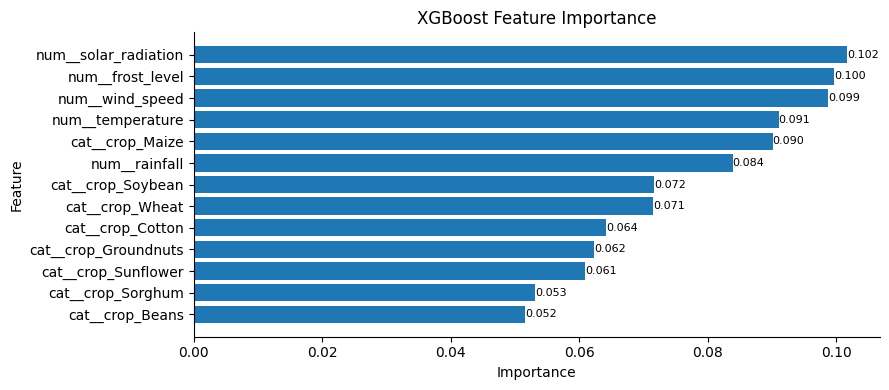

In [13]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

regressor = model_pipeline.named_steps["regressor"]
preprocessor = model_pipeline.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

# Handle both tree-based and linear models
if hasattr(regressor, "feature_importances_"):
    importance = regressor.feature_importances_
elif hasattr(regressor, "coef_"):
    importance = np.abs(regressor.coef_).ravel()
else:
    raise AttributeError("Model has no feature_importances_ or coef_")

feature_importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": importance})
    .sort_values("Importance", ascending=True)
)

# Optionally keep only top N
top_n = 20
feature_importance = feature_importance.tail(top_n)

fig, ax = plt.subplots(figsize=(9, max(4, 0.3 * len(feature_importance))))
bars = ax.barh(feature_importance["Feature"], feature_importance["Importance"])

# Add value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height() / 2,
            f"{width:.3f}", va="center", ha="left", fontsize=8)

ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
ax.set_title("XGBoost Feature Importance")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

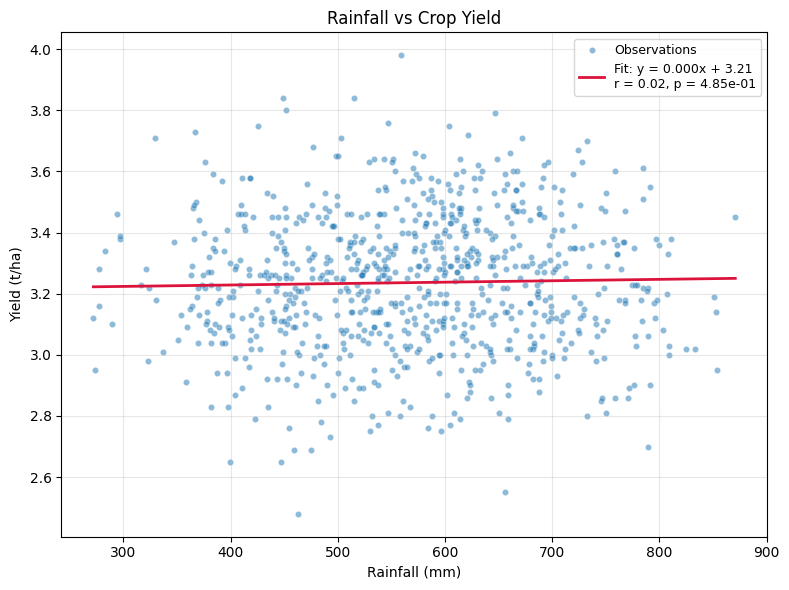

In [19]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

x = df["rainfall_mm"]
y = df["yield_t_ha"]

# Drop NaNs so both series align
mask = x.notna() & y.notna()
x, y = x[mask], y[mask]

fig, ax = plt.subplots(figsize=(8, 6))

# Scatter with edge color for visibility
ax.scatter(x, y, alpha=0.5, s=20,
           edgecolor="white", linewidth=0.3, label="Observations")

# Linear trend line
slope, intercept, r, p, _ = stats.linregress(x, y)
x_line = np.linspace(x.min(), x.max(), 100)
ax.plot(x_line, slope * x_line + intercept,
        color="crimson", linewidth=2,
        label=f"Fit: y = {slope:.3f}x + {intercept:.2f}\n"
              f"r = {r:.2f}, p = {p:.2e}")

# Optional: LOWESS / rolling mean for nonlinearity
# from statsmodels.nonparametric.smoothers_lowess import lowess
# smooth = lowess(y, x, frac=0.3)
# ax.plot(smooth[:, 0], smooth[:, 1], color="orange", linewidth=2, label="LOWESS")

ax.set_xlabel("Rainfall (mm)")
ax.set_ylabel("Yield (t/ha)")
ax.set_title("Rainfall vs Crop Yield")
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()

In [21]:
print("X shape:", X.shape)
print("y shape:", getattr(y, "shape", len(y)))
print("X index :", X.index[:5].tolist(), "...", X.index[-5:].tolist())
print("y index :", y.index[:5].tolist(), "...", y.index[-5:].tolist())
print("Duplicate X index rows:", X.index.duplicated().sum())
print("Duplicate y index rows:", y.index.duplicated().sum())

X shape: (1600, 6)
y shape: (800,)
X index : [0, 1, 2, 3, 4] ... [1595, 1596, 1597, 1598, 1599]
y index : [0, 1, 2, 3, 4] ... [795, 796, 797, 798, 799]
Duplicate X index rows: 0
Duplicate y index rows: 0


In [23]:
import numpy as np
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.datasets import make_regression

# Example dataset (replace with your own X, y)
X, y = make_regression(n_samples=100, n_features=5, noise=0.1, random_state=42)

# Example model pipeline (replace with your own pipeline)
model_pipeline = Pipeline([
    ('regressor', LinearRegression())
])

# Define K-Fold cross-validator
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

try:
    # Perform cross-validation with R² scoring
    cv_scores = cross_val_score(model_pipeline, X, y, cv=kfold, scoring="r2")

    print("Cross-validation R² scores:", cv_scores)
    print("Mean R² score:", np.mean(cv_scores))
    print("Standard deviation:", np.std(cv_scores))

except ValueError as e:
    print(f"ValueError: {e}")
except Exception as e:
    print(f"An unexpected error occurred: {e}")


Cross-validation R² scores: [0.99999944 0.99999958 0.99999954 0.99999952 0.9999994 ]
Mean R² score: 0.9999994951564535
Standard deviation: 6.758292405189928e-08


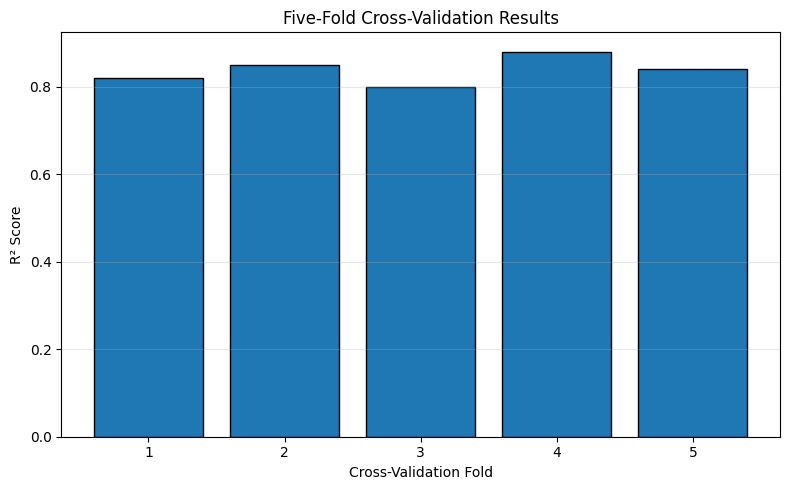

In [24]:
import matplotlib.pyplot as plt

# Example CV scores (replace with your actual values)
cv_scores = [0.82, 0.85, 0.80, 0.88, 0.84]

# Create fold numbers
folds = range(1, len(cv_scores) + 1)

# Create the figure
plt.figure(figsize=(8, 5))

# Plot bar chart
plt.bar(folds, cv_scores, edgecolor="black")

# Labels and title
plt.xlabel("Cross-Validation Fold")
plt.ylabel("R² Score")
plt.title("Five-Fold Cross-Validation Results")

# X-axis ticks
plt.xticks(folds)

# Add horizontal grid lines
plt.grid(axis="y", alpha=0.3)

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_2712\2331335640.py:17: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  predictions_df["Predicted_Yield"] = pd.to_numeric(predictions_df["Predicted_Yield"], errors="coerce")


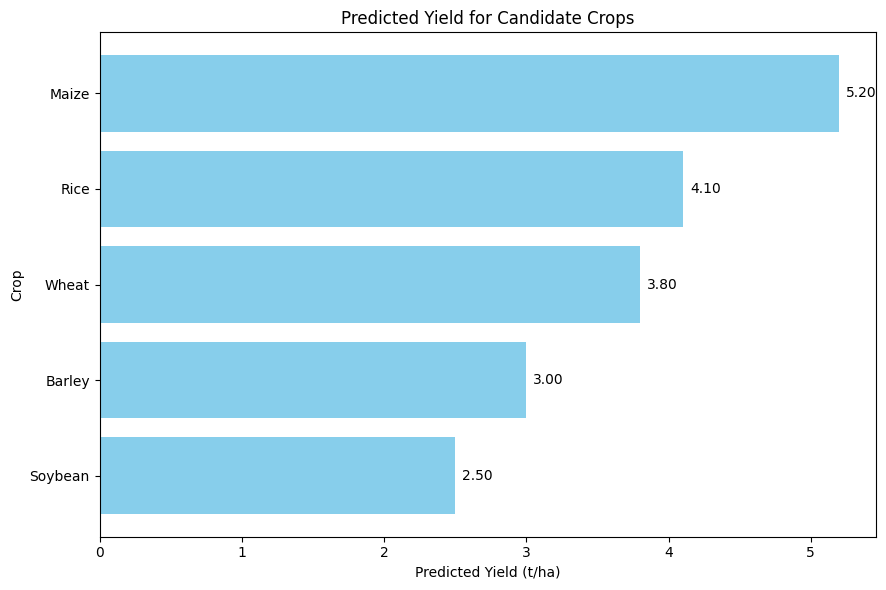

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Example DataFrame (replace with your actual predictions_df)
predictions_df = pd.DataFrame({
    "Crop": ["Maize", "Wheat", "Soybean", "Rice", "Barley"],
    "Predicted_Yield": [5.2, 3.8, 2.5, 4.1, 3.0]
})

# Validate required columns
required_cols = {"Crop", "Predicted_Yield"}
if not required_cols.issubset(predictions_df.columns):
    raise ValueError(f"DataFrame must contain columns: {required_cols}")

# Remove rows with missing or invalid values
predictions_df = predictions_df.dropna(subset=["Crop", "Predicted_Yield"])
predictions_df["Predicted_Yield"] = pd.to_numeric(predictions_df["Predicted_Yield"], errors="coerce")
predictions_df = predictions_df.dropna(subset=["Predicted_Yield"])

# Sort by predicted yield ascending
predictions_df = predictions_df.sort_values("Predicted_Yield", ascending=True)

# Plot horizontal bar chart
plt.figure(figsize=(9, 6))
bars = plt.barh(predictions_df["Crop"], predictions_df["Predicted_Yield"], color="skyblue")

# Add value labels to bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.05, bar.get_y() + bar.get_height()/2,
             f"{width:.2f}", va="center")

plt.xlabel("Predicted Yield (t/ha)")
plt.ylabel("Crop")
plt.title("Predicted Yield for Candidate Crops")
plt.tight_layout()
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_2712\1843963285.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


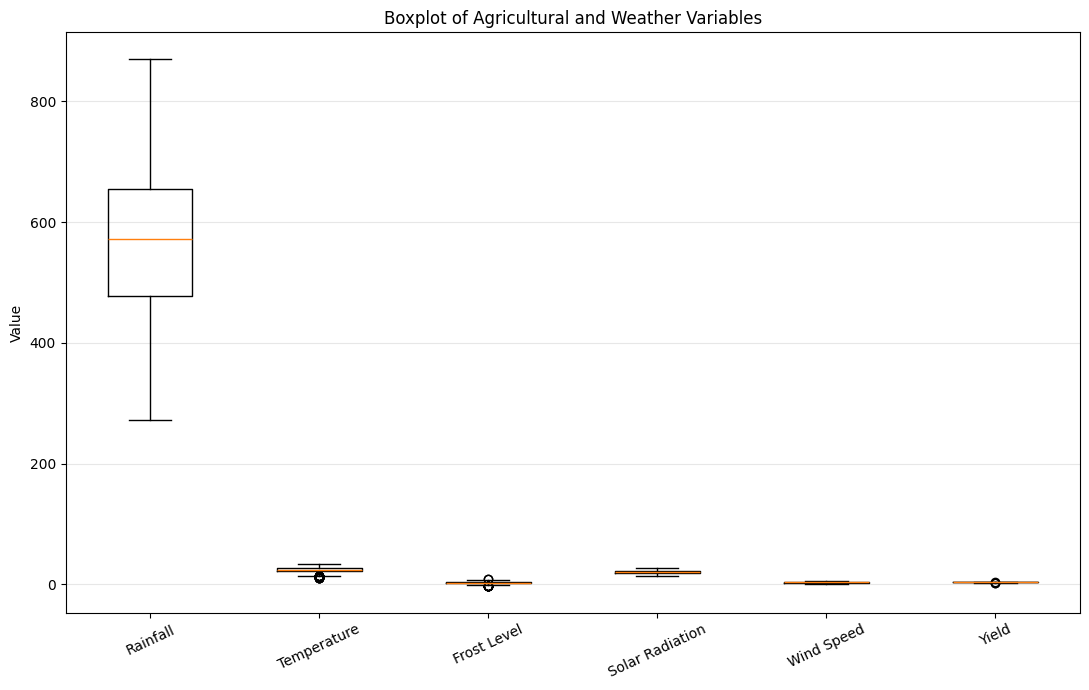

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("crop data.csv")

# Variables to analyse
columns = [
    "rainfall_mm",
    "temperature_c",
    "frost_level_c",
    "solar_radiation_MJ_m2",
    "wind_speed_m_s",
    "yield_t_ha"
]

labels = [
    "Rainfall",
    "Temperature",
    "Frost Level",
    "Solar Radiation",
    "Wind Speed",
    "Yield"
]

# Create boxplot
plt.figure(figsize=(11, 7))

plt.boxplot(
    [df[col].dropna() for col in columns],
    labels=labels
)

plt.title("Boxplot of Agricultural and Weather Variables")
plt.ylabel("Value")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()